<a href="https://colab.research.google.com/github/SabaNibladze/pet-breed-classifier/blob/main/pet_breed_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import torch

print("PyTorch ვერსია:", torch.__version__)
print("GPU ხელმისაწვდომია:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch ვერსია: 2.11.0+cu130
GPU ხელმისაწვდომია: True
GPU: Tesla T4


In [3]:
from torchvision.datasets import OxfordIIITPet

dataset = OxfordIIITPet(root="data", split="trainval", target_types="category", download=True)

print("სურათების რაოდენობა:", len(dataset))
print("ჯიშების რაოდენობა:", len(dataset.classes))
print("პირველი 5 ჯიში:", dataset.classes[:5])

100%|██████████| 792M/792M [00:45<00:00, 17.5MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 10.2MB/s]


სურათების რაოდენობა: 3680
ჯიშების რაოდენობა: 37
პირველი 5 ჯიში: ['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle']


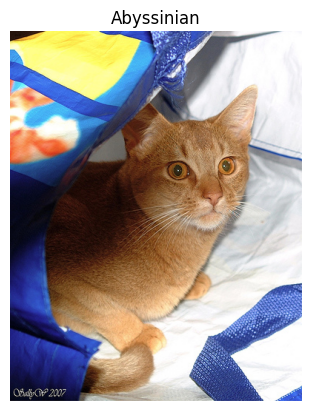

სურათის ზომა: (394, 500)


In [4]:
import matplotlib.pyplot as plt

img, label = dataset[0]
plt.imshow(img)
plt.title(dataset.classes[label])
plt.axis("off")
plt.show()
print("სურათის ზომა:", img.size)

In [5]:
import torch
from torch.utils.data import Subset, DataLoader
from torchvision import transforms
from torchvision.datasets import OxfordIIITPet

IMG_SIZE = 224
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

full_train = OxfordIIITPet(root="data", split="trainval", target_types="category", transform=train_tf)
full_val   = OxfordIIITPet(root="data", split="trainval", target_types="category", transform=eval_tf)
test_ds    = OxfordIIITPet(root="data", split="test",     target_types="category", transform=eval_tf)

g = torch.Generator().manual_seed(42)
perm = torch.randperm(len(full_train), generator=g).tolist()
n_val = int(0.2 * len(perm))
val_idx, train_idx = perm[:n_val], perm[n_val:]

train_ds = Subset(full_train, train_idx)
val_ds   = Subset(full_val, val_idx)

print("train:", len(train_ds), "| val:", len(val_ds), "| test:", len(test_ds))

train: 2944 | val: 736 | test: 3669


In [6]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

images, labels = next(iter(train_loader))
print("images:", images.shape)
print("labels:", labels.shape)

images: torch.Size([32, 3, 224, 224])
labels: torch.Size([32])


In [7]:
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def build_model(num_classes=37, freeze_backbone=True):
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    if freeze_backbone:
        for p in model.parameters():
            p.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model.to(device)

model = build_model()

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"სულ პარამეტრები: {total:,} | გასაწვრთნელი: {trainable:,}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 75.9MB/s]


სულ პარამეტრები: 11,195,493 | გასაწვრთნელი: 18,981


In [8]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            n += images.size(0)
    return total_loss / n, correct / n

In [9]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    [p for p in model.parameters() if p.requires_grad], lr=1e-3
)

EPOCHS = 5
for epoch in range(EPOCHS):
    tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
    va_loss, va_acc = run_epoch(model, val_loader, criterion)
    print(f"epoch {epoch+1}/{EPOCHS} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | val loss {va_loss:.3f} acc {va_acc:.3f}")

epoch 1/5 | train loss 2.070 acc 0.537 | val loss 1.131 acc 0.755
epoch 2/5 | train loss 0.797 acc 0.850 | val loss 0.716 acc 0.822
epoch 3/5 | train loss 0.542 acc 0.886 | val loss 0.552 acc 0.863
epoch 4/5 | train loss 0.435 acc 0.904 | val loss 0.491 acc 0.867
epoch 5/5 | train loss 0.365 acc 0.918 | val loss 0.444 acc 0.879


In [10]:
import time, copy

# თუ results უკვე არსებობს, არ ვშლით (რომ fine-tuning-ის შედეგი არ დაიკარგოს)
if "results" not in globals():
    results = {}

results["baseline_frozen_resnet18"] = {"val_acc": 0.875, "trainable_params": 18981}

def run_experiment(name, model, lr, epochs=5):
    criterion = nn.CrossEntropyLoss()
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(params, lr=lr)
    best_acc, best_state = 0.0, None
    start = time.time()
    for epoch in range(epochs):
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        print(f"{name} | epoch {epoch+1}/{epochs} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | val loss {va_loss:.3f} acc {va_acc:.3f}")
        if va_acc > best_acc:
            best_acc = va_acc
            best_state = copy.deepcopy(model.state_dict())
    minutes = (time.time() - start) / 60
    torch.save(best_state, f"{name}.pth")
    results[name] = {
        "val_acc": round(best_acc, 4),
        "trainable_params": sum(p.numel() for p in params),
        "minutes": round(minutes, 1),
    }
    print("შედეგი:", results[name])

In [11]:
model_ft = build_model(freeze_backbone=False)
run_experiment("finetune_resnet18", model_ft, lr=1e-4)

finetune_resnet18 | epoch 1/5 | train loss 1.771 acc 0.614 | val loss 0.849 acc 0.833
finetune_resnet18 | epoch 2/5 | train loss 0.525 acc 0.913 | val loss 0.518 acc 0.882
finetune_resnet18 | epoch 3/5 | train loss 0.270 acc 0.958 | val loss 0.394 acc 0.908
finetune_resnet18 | epoch 4/5 | train loss 0.164 acc 0.977 | val loss 0.373 acc 0.901
finetune_resnet18 | epoch 5/5 | train loss 0.107 acc 0.987 | val loss 0.378 acc 0.895
შედეგი: {'val_acc': 0.9076, 'trainable_params': 11195493, 'minutes': 1.6}


In [12]:
import os

def build_mobilenet(num_classes=37):
    m = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT)
    m.classifier[3] = nn.Linear(m.classifier[3].in_features, num_classes)
    return m.to(device)

model_mb = build_mobilenet()
print("პარამეტრები:", f"{sum(p.numel() for p in model_mb.parameters()):,}")
run_experiment("finetune_mobilenetv3small", model_mb, lr=3e-4)

for name in ["finetune_resnet18", "finetune_mobilenetv3small"]:
    print(name, "| ფაილის ზომა:", round(os.path.getsize(f"{name}.pth") / 1e6, 1), "MB")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 134MB/s]

პარამეტრები: 1,555,781


finetune_mobilenetv3small | epoch 1/5 | train loss 2.050 acc 0.490 | val loss 1.085 acc 0.652
finetune_mobilenetv3small | epoch 2/5 | train loss 0.619 acc 0.818 | val loss 0.650 acc 0.798
finetune_mobilenetv3small | epoch 3/5 | train loss 0.329 acc 0.905 | val loss 0.651 acc 0.803
finetune_mobilenetv3small | epoch 4/5 | train loss 0.237 acc 0.931 | val loss 0.711 acc 0.783
finetune_mobilenetv3small | epoch 5/5 | train loss 0.143 acc 0.959 | val loss 0.642 acc 0.822
შედეგი: {'val_acc': 0.822, 'trainable_params': 1555781, 'minutes': 1.5}
finetune_resnet18 | ფაილის ზომა: 44.9 MB
finetune_mobilenetv3small | ფაილის ზომა: 6.4 MB


In [13]:
import json, shutil, os
from google.colab import drive

drive.mount('/content/drive')
save_dir = "/content/drive/MyDrive/pet_project"
os.makedirs(save_dir, exist_ok=True)

with open("results.json", "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2, ensure_ascii=False)

for fn in ["results.json", "finetune_resnet18.pth", "finetune_mobilenetv3small.pth"]:
    shutil.copy(fn, save_dir)

print("Drive-ში შენახულია:", os.listdir(save_dir))

Mounted at /content/drive
Drive-ში შენახულია: ['finetune_resnet18.pth', 'finetune_mobilenetv3small.pth', 'resnet18_pets.onnx', 'results.json']


In [14]:
from collections import Counter
import numpy as np

best = build_model(freeze_backbone=False)
best.load_state_dict(torch.load("finetune_resnet18.pth", map_location=device))
best.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in test_loader:
        outputs = best(images.to(device))
        all_preds.extend(outputs.argmax(1).cpu().tolist())
        all_labels.extend(labels.tolist())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)
test_acc = (all_preds == all_labels).mean()
print(f"TEST accuracy: {test_acc:.4f}")

pairs = Counter()
for t, p in zip(all_labels, all_preds):
    if t != p:
        pairs[(dataset.classes[t], dataset.classes[p])] += 1

print("\nყველაზე ხშირი შეცდომები:")
for (t, p), c in pairs.most_common(8):
    print(f"{c:2d}x  სწორი: {t}  ->  მოდელმა თქვა: {p}")

results["finetune_resnet18"]["test_acc"] = round(float(test_acc), 4)

TEST accuracy: 0.8656

ყველაზე ხშირი შეცდომები:
19x  სწორი: American Pit Bull Terrier  ->  მოდელმა თქვა: American Bulldog
18x  სწორი: American Pit Bull Terrier  ->  მოდელმა თქვა: Staffordshire Bull Terrier
15x  სწორი: Staffordshire Bull Terrier  ->  მოდელმა თქვა: American Bulldog
13x  სწორი: Egyptian Mau  ->  მოდელმა თქვა: Bengal
12x  სწორი: Pug  ->  მოდელმა თქვა: Boxer
12x  სწორი: Ragdoll  ->  მოდელმა თქვა: Birman
10x  სწორი: Birman  ->  მოდელმა თქვა: Siamese
 9x  სწორი: Chihuahua  ->  მოდელმა თქვა: Sphynx


In [15]:
import time, os, copy
import numpy as np

def evaluate(model, loader):
    model.eval()
    correct, n = 0, 0
    with torch.no_grad():
        for images, labels in loader:
            out = model(images.to(device))
            correct += (out.argmax(1).cpu() == labels).sum().item()
            n += labels.size(0)
    return correct / n

def cpu_latency_ms(model, runs=30):
    m = copy.deepcopy(model).to("cpu").eval()
    x = torch.randn(1, 3, 224, 224)
    times = []
    with torch.no_grad():
        for _ in range(5):
            m(x)
        for _ in range(runs):
            t = time.perf_counter()
            m(x)
            times.append((time.perf_counter() - t) * 1000)
    return float(np.median(times))

mb = build_mobilenet()
mb.load_state_dict(torch.load("finetune_mobilenetv3small.pth", map_location=device))
results["finetune_mobilenetv3small"]["test_acc"] = round(evaluate(mb, test_loader), 4)

for key, m, f in [("finetune_resnet18", best, "finetune_resnet18.pth"),
                  ("finetune_mobilenetv3small", mb, "finetune_mobilenetv3small.pth")]:
    results[key]["cpu_ms"] = round(cpu_latency_ms(m), 1)
    results[key]["size_mb"] = round(os.path.getsize(f) / 1e6, 1)
    print(key, "|", {k: results[key][k] for k in ["test_acc", "size_mb", "cpu_ms"]})

finetune_resnet18 | {'test_acc': 0.8656, 'size_mb': 44.9, 'cpu_ms': 56.7}
finetune_mobilenetv3small | {'test_acc': 0.7781, 'size_mb': 6.4, 'cpu_ms': 10.2}


In [16]:
!pip install -q onnx onnxruntime onnxscript

import onnxruntime as ort

m_cpu = copy.deepcopy(best).to("cpu").eval()
dummy = torch.randn(1, 3, 224, 224)

torch.onnx.export(
    m_cpu, dummy, "resnet18_pets.onnx",
    input_names=["image"], output_names=["logits"],
    dynamic_axes={"image": {0: "batch"}, "logits": {0: "batch"}},
    opset_version=17, dynamo=False,
)

sess = ort.InferenceSession("resnet18_pets.onnx", providers=["CPUExecutionProvider"])
x = np.random.randn(1, 3, 224, 224).astype(np.float32)

with torch.no_grad():
    ref = m_cpu(torch.from_numpy(x)).numpy()
out = sess.run(None, {"image": x})[0]
print("მაქს. განსხვავება:", float(np.abs(ref - out).max()))

for _ in range(5):
    sess.run(None, {"image": x})
times = []
for _ in range(30):
    t = time.perf_counter()
    sess.run(None, {"image": x})
    times.append((time.perf_counter() - t) * 1000)

results["finetune_resnet18"]["onnx_cpu_ms"] = round(float(np.median(times)), 1)
results["finetune_resnet18"]["onnx_size_mb"] = round(os.path.getsize("resnet18_pets.onnx") / 1e6, 1)

print("PyTorch CPU:", results["finetune_resnet18"]["cpu_ms"], "ms")
print("ONNX CPU:   ", results["finetune_resnet18"]["onnx_cpu_ms"], "ms")
print("ONNX ზომა:  ", results["finetune_resnet18"]["onnx_size_mb"], "MB")

with open("results.json", "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2, ensure_ascii=False)
shutil.copy("results.json", save_dir)
shutil.copy("resnet18_pets.onnx", save_dir)

/tmp/ipykernel_1088/2764769891.py:8: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


მაქს. განსხვავება: 2.2351741790771484e-07
PyTorch CPU: 56.7 ms
ONNX CPU:    34.1 ms
ONNX ზომა:   44.8 MB


'/content/drive/MyDrive/pet_project/resnet18_pets.onnx'

In [17]:
import gradio as gr
import os
from torchvision.datasets import OxfordIIITPet

# ძველი დემოს დახურვა, თუ ჯერ ჩართულია
try:
    demo.close()
except Exception:
    pass

# მაგალითი სურათები test ნაკრებიდან
raw_test = OxfordIIITPet(root="data", split="test", target_types="category")
os.makedirs("examples", exist_ok=True)
example_paths = []
for k, i in enumerate([0, 400, 900, 1500, 2200, 3000]):
    img, _ = raw_test[i]
    p = f"examples/example_{k}.jpg"
    img.convert("RGB").save(p)
    example_paths.append(p)

preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
classes = dataset.classes
best.eval()

def predict(img):
    if img is None:
        return {}
    x = preprocess(img.convert("RGB")).unsqueeze(0).to(device)
    with torch.no_grad():
        probs = torch.softmax(best(x), dim=1)[0]
    top = torch.topk(probs, 3)
    return {classes[i]: float(p) for p, i in zip(top.values.cpu(), top.indices.cpu())}

with gr.Blocks(theme=gr.themes.Soft()) as demo:
    gr.Markdown(
        "# 🐾 Pet Breed Classifier\n"
        "ატვირთეთ კატის ან ძაღლის ფოტო და მოდელი 37 ჯიშიდან ამოიცნობს მას.  \n"
        "**მოდელი:** ResNet18 (fine-tuned) · **მონაცემები:** Oxford-IIIT Pet · **Test accuracy:** 85.7%"
    )
    with gr.Row():
        with gr.Column():
            inp = gr.Image(type="pil", label="ატვირთეთ ცხოველის ფოტო")
            btn = gr.Button("ამოიცანი ჯიში", variant="primary")
        with gr.Column():
            out = gr.Label(num_top_classes=3, label="ყველაზე სავარაუდო ჯიშები")
    gr.Examples(examples=example_paths, inputs=inp, label="სცადეთ მაგალითები")
    btn.click(predict, inputs=inp, outputs=out)

demo.launch(share=True)

/tmp/ipykernel_1088/2861874783.py:38: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()

Could not create share link. Please check your internet connection or our status page: https://status.gradio.app.


2026/10/29 12:20:37 [W] [service.go:132] login to server failed: dial tcp 44.237.78.176:7000: connect: connection refused


<IPython.core.display.Javascript object>

ჯიშზე სურათების რაოდენობა: მინიმუმ 93 | მაქსიმუმ 100 | საშუალოდ 99.5

macro precision 0.874 | macro recall 0.865 | macro F1 0.863
ყველაზე სუსტი 5 ჯიში (F1): [('American Pit Bull Terrier', 0.56), ('Staffordshire Bull Terrier', 0.63), ('Chihuahua', 0.75), ('American Bulldog', 0.76), ('Boxer', 0.79)]
ყველაზე ძლიერი 3 ჯიში (F1): [('Keeshond', 0.99), ('Leonberger', 0.97), ('Yorkshire Terrier', 0.96)]


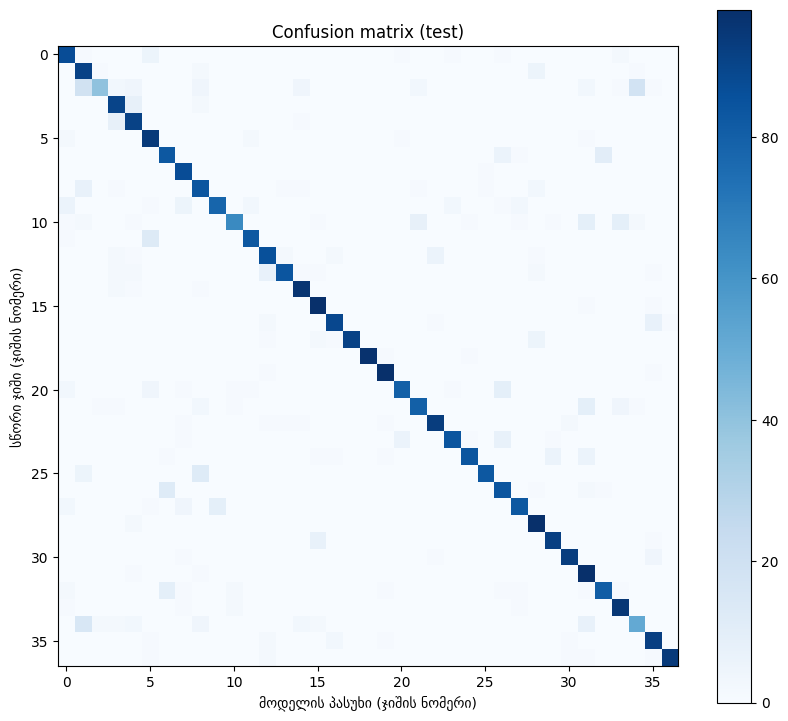


შენახულია.


In [18]:
import numpy as np
from collections import Counter
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

try:
    labels_all = list(dataset._labels)
except AttributeError:
    labels_all = [dataset[i][1] for i in range(len(dataset))]
counts = Counter(labels_all)
print("ჯიშზე სურათების რაოდენობა: მინიმუმ", min(counts.values()),
      "| მაქსიმუმ", max(counts.values()),
      "| საშუალოდ", round(len(labels_all) / len(counts), 1))

report = classification_report(all_labels, all_preds,
                               target_names=dataset.classes,
                               output_dict=True, digits=4)
macro = report["macro avg"]
print(f"\nmacro precision {macro['precision']:.3f} | "
      f"macro recall {macro['recall']:.3f} | macro F1 {macro['f1-score']:.3f}")

per_class = {c: report[c]["f1-score"] for c in dataset.classes}
worst = sorted(per_class.items(), key=lambda kv: kv[1])[:5]
best_ = sorted(per_class.items(), key=lambda kv: kv[1], reverse=True)[:3]
print("ყველაზე სუსტი 5 ჯიში (F1):", [(c, round(v, 2)) for c, v in worst])
print("ყველაზე ძლიერი 3 ჯიში (F1):", [(c, round(v, 2)) for c, v in best_])

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(10, 9))
plt.imshow(cm, cmap="Blues")
plt.title("Confusion matrix (test)")
plt.xlabel("მოდელის პასუხი (ჯიშის ნომერი)")
plt.ylabel("სწორი ჯიში (ჯიშის ნომერი)")
plt.colorbar()
plt.show()

results["finetune_resnet18"]["macro_f1"] = round(float(macro["f1-score"]), 4)
with open("results.json", "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2, ensure_ascii=False)
shutil.copy("results.json", save_dir)
print("\nშენახულია.")